# **Nama Anggota Kelompok**
- Ranya Salma Aqila
- Raihan Fawwaz Naufal
- Naila Hariri
- Rubben Siahaan

# **Deskripsi Proyek Kelompok**
Proyek final ini menggunakan dataset Coffee Shop Transaction buat analisis clustering pakai K-Means. Tujuannya buat mengelompokkan pelanggan berdasarkan transaksi mereka, seperti total penjualan, jumlah produk, dan harga unit. Silhouette Score digunakan buat ngecek kualitas clustering, supaya hasilnya jelas dan terpisah dengan baik.

Setelah clustering, kita analisis kelompok pelanggan berdasarkan pola pembelian, seperti pelanggan dengan pembelian tinggi atau yang sering beli produk premium. Untuk nambah wawasan, kita pakai Large Language Model (LLM) buat menjelaskan otomatis tiap cluster dan memberikan insight lebih dalam soal karakteristik kelompok pelanggan.

# **Langkah 1: Import Library yang Dibutuhkan**
Di langkah pertama, kita mengimpor berbagai library atau pustaka yang diperlukan untuk menganalisis data, membuat model clustering, dan mengintegrasikan hasilnya dengan LLM untuk interpretasi.

- Pandas digunakan untuk manipulasi data, seperti membaca dataset, membersihkan data, dan memanipulasi kolom.
- Matplotlib dan Seaborn digunakan untuk membuat grafik dan visualisasi data, membantu kita memahami pola dan distribusi data.
- Scikit-learn digunakan untuk preprocessing (seperti normalisasi data), algoritma KMeans untuk clustering, dan evaluasi clustering dengan Silhouette Score.
- PCA digunakan untuk reduksi dimensi agar clustering lebih efektif dan mempermudah visualisasi data.
- Tabulate membantu menyusun hasil analisis dalam bentuk tabel yang rapi.
- LangChain dan Google Gemini AI digunakan untuk menghasilkan interpretasi hasil clustering secara otomatis menggunakan model LLM (Large Language Model) yang dapat memberikan penjelasan dan analisis yang mendalam.

In [ ]:
# Mengimpor library yang diperlukan untuk analisis data, clustering, dan integrasi LLM
import pandas as pd  # Untuk manipulasi data
import matplotlib.pyplot as plt  # Untuk visualisasi data
import seaborn as sns  # Untuk visualisasi data

from sklearn.preprocessing import MinMaxScaler  # Untuk normalisasi data
from sklearn.cluster import KMeans  # Algoritma clustering K-Means
from sklearn.metrics import silhouette_score  # Evaluasi clustering dengan Silhouette Score
from sklearn.decomposition import PCA  # Reduksi dimensi untuk mempermudah clustering
from tabulate import tabulate  # Untuk menampilkan data dalam tabel
from getpass import getpass  # Untuk input API key secara aman
from mpl_toolkits.mplot3d import Axes3D  # Untuk visualisasi data 3D

# Import library untuk integrasi LLM (Google Gemini dengan LangChain)
from langchain_google_genai.chat_models import ChatGoogleGenerativeAI  # Model Google Gemini AI
from langchain.prompts import ChatPromptTemplate  # Membuat prompt untuk LLM
from langchain.chains import LLMChain  # Untuk menjalankan LLM

# **Langkah 2: Memuat Dataset**

Pada langkah ini, kita memuat dataset yang berisi informasi transaksi dari file CSV menggunakan Pandas.

- Pandas digunakan untuk membaca data dari file CSV yang disediakan, memastikan kita bisa melakukan manipulasi data dengan mudah.
- Setelah data dimuat, kita tampilkan beberapa baris pertama untuk memeriksa data dan memastikan bahwa semuanya sudah benar.


In [ ]:
# Memuat dataset dari file CSV
df = pd.read_csv('/content/drive/MyDrive/FINAL PROJECT MSIB 7 CELERATES/coffeeshop_transactions_2023.csv')

In [ ]:
# Menampilkan 5 baris pertama dataset untuk memastikan berhasil dimuat
display(df.head())

,transaction_date,product_name,unit_price,total_qty,city,discount%
0,2023-11-27,Espresso,25000,3,Jakarta,20
1,2023-12-13,Cappuccino,30000,1,Bandung,5
2,2023-11-28,Latte,35000,5,Yogyakarta,15
3,2023-07-24,Espresso,25000,1,Jakarta,20
4,2023-06-19,Sandwich,45000,5,Bandung,0


# **Langkah 3: Menampilkan Informasi Dataset**
Di langkah ini, kita memeriksa struktur dan statistik dasar dataset menggunakan Pandas.

- Menggunakan df.info() untuk menampilkan informasi tipe data dan jumlah nilai kosong di setiap kolom.
- Menggunakan df.describe() untuk melihat statistik deskriptif dari data numerik.
- Menggunakan df.isnull().sum() untuk menghitung jumlah nilai kosong di setiap kolom.


In [ ]:
df.info()  # Menampilkan struktur dataset

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 750 entries, 0 to 749
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   transaction_date  750 non-null    object
 1   product_name      750 non-null    object
 2   unit_price        750 non-null    int64 
 3   total_qty         750 non-null    int64 
 4   city              750 non-null    object
 5   discount%         750 non-null    int64 
dtypes: int64(3), object(3)
memory usage: 35.3+ KB


In [ ]:
df.describe()  # Statistik deskriptif dataset

,unit_price,total_qty,discount%
count,750.000000,750.000000,750.000000
mean,31938.666667,3.090667,10.073333
std,10253.084375,1.427292,7.020946
min,15000.000000,1.000000,0.000000
25%,25000.000000,2.000000,5.000000
50%,30000.000000,3.000000,10.000000
75%,40000.000000,4.000000,15.000000
max,50000.000000,5.000000,20.000000


In [ ]:
print("Missing values per column:\n", df.isnull().sum())  # Jumlah nilai kosong per kolom

Missing values per column:
 transaction_date    0
product_name        0
unit_price          0
total_qty           0
city                0
discount%           0
dtype: int64


# **Langkah 4: Preprocessing Data**
Pada langkah ini, kita membersihkan data dan menyiapkannya untuk analisis lebih lanjut dengan beberapa langkah berikut:

- Menghapus data duplikat.
- Menghapus baris dengan nilai negatif pada harga atau jumlah produk yang tidak logis.
- Mengisi nilai kosong pada kolom discount% dengan rata-rata nilai kolom tersebut.
- Menambahkan Fitur Baru: Rasio Pembelian per Transaksi
- Menghapus baris yang memiliki nilai kosong di kolom yang penting.
Menambahkan kolom baru untuk analisis, seperti total_sales dan month
- MinMaxScaler digunakan untuk mengubah data dalam rentang [0, 1], memastikan bahwa setiap fitur memiliki skala yang setara.
- Membuat pairplot untuk mengecek distribusi dari visualisasi data setelah di preprocessing



In [ ]:
# Membersihkan dataset dengan langkah-langkah berikut:
# Menghapus data duplikat
print("Sebelum preprocessing:", len(df))
df = df.drop_duplicates()

Sebelum preprocessing: 750


In [ ]:
# Menghapus data dengan nilai negatif pada harga atau jumlah
df = df[(df['unit_price'] > 0) & (df['total_qty'] > 0)]

In [ ]:
# Mengisi nilai kosong pada 'discount%' dengan rata-rata
if 'discount%' in df.columns:
    df['discount%'] = df['discount%'].fillna(df['discount%'].mean())

In [ ]:
# Menghapus baris dengan nilai kosong pada kolom penting lainnya
df.dropna(inplace=True)
print("Jumlah data setelah preprocessing:", len(df))

Jumlah data setelah preprocessing: 750


In [ ]:
# Menambahkan kolom tambahan untuk analisis
df['total_sales'] = df['unit_price'] * df['total_qty']
df['average_price_per_unit'] = df['total_sales'] / df['total_qty']  # Harga rata-rata per unit
df['month'] = pd.to_datetime(df['transaction_date']).dt.month
df['day_of_week'] = pd.to_datetime(df['transaction_date']).dt.dayofweek

In [ ]:
# Menampilkan 5 baris pertama untuk memastikan fitur baru berhasil ditambahkan
# Rasio ini dihitung sebagai total_sales / total_qty
df['average_price_per_unit'] = df['total_sales'] / df['total_qty']
print(df[['total_sales', 'total_qty', 'average_price_per_unit']].head())

   total_sales  total_qty  average_price_per_unit
0        75000          3                 25000.0
1        30000          1                 30000.0
2       175000          5                 35000.0
3        25000          1                 25000.0
4       225000          5                 45000.0


# **Normalisasi Data Numerik**
- Menggunakan MinMaxScaler untuk mengubah data ke rentang [0, 1]

In [ ]:
# Menggunakan MinMaxScaler untuk normalisasi data
scaler = MinMaxScaler()
numeric_features = ['unit_price', 'total_qty', 'total_sales', 'discount%', 'average_price_per_unit']  # Menambahkan average_price_per_unit
df[numeric_features] = scaler.fit_transform(df[numeric_features])

# **Visualisasi Distribusi Data Setelah Preprocessing**
- Menggunakan pairplot untuk melihat distribusi fitur numerik

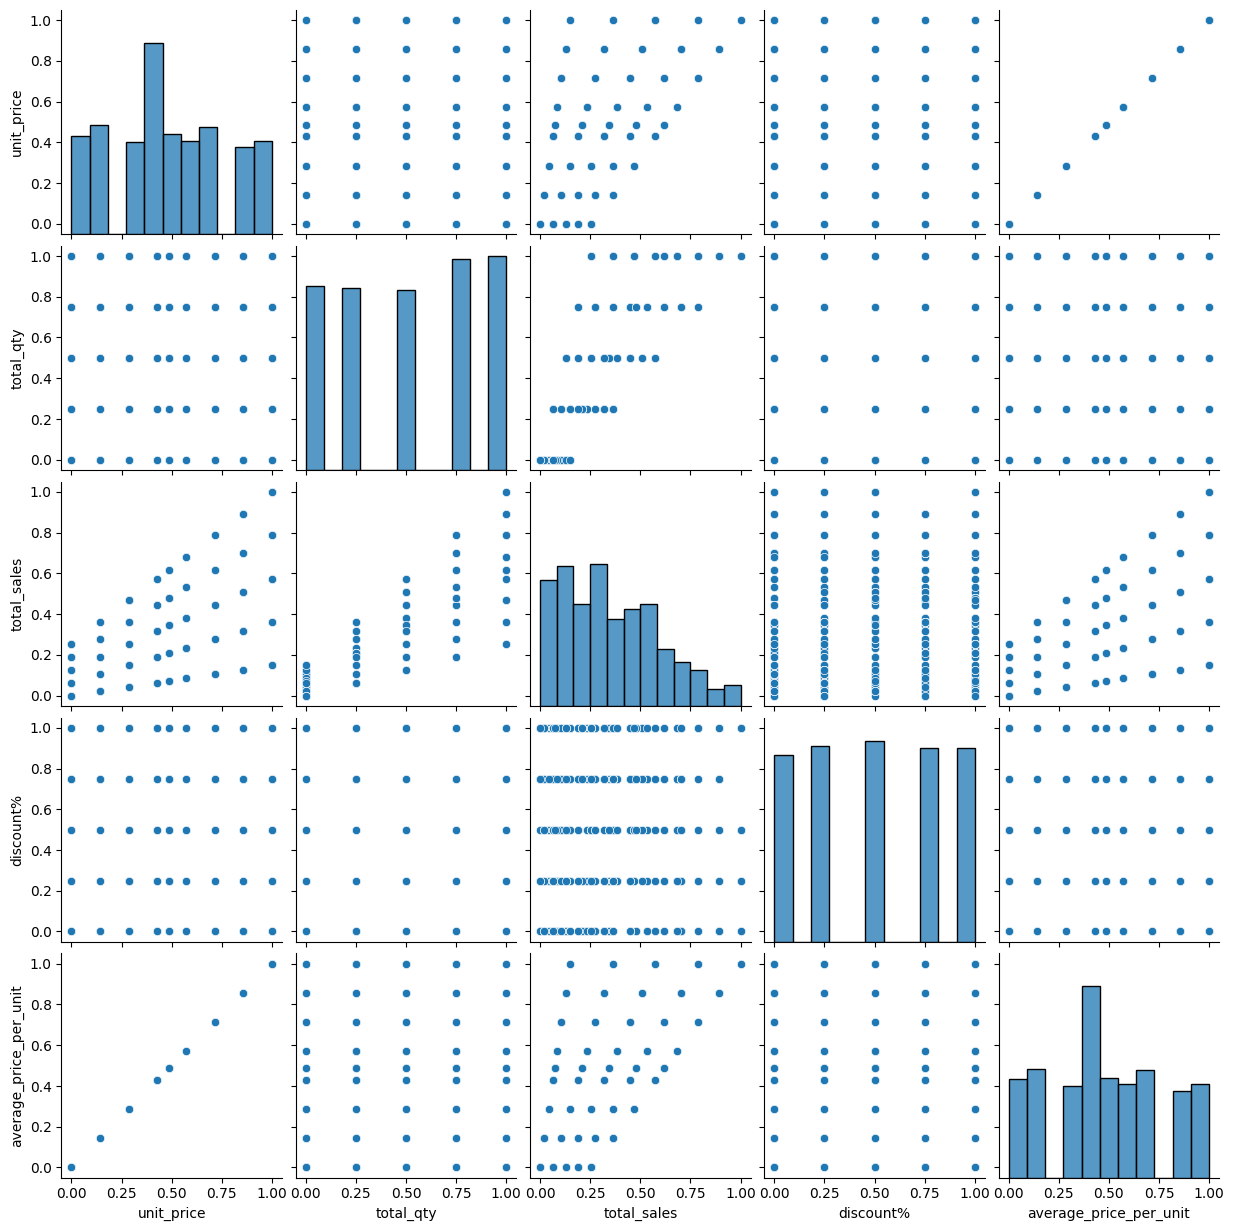

In [ ]:
# Visualisasi distribusi data setelah preprocessing
sns.pairplot(df[numeric_features])  # Membuat pairplot untuk mengecek distribusi
plt.show()

# **Langkah 5: Reduksi Dimensi dengan PCA**
- Untuk mempermudah proses clustering dan visualisasi, kita melakukan reduksi dimensi dengan menggunakan PCA (Principal Component Analysis). - Ini mengurangi jumlah fitur tanpa kehilangan banyak informasi.

In [ ]:
# Reduksi dimensi menggunakan PCA untuk mempermudah clustering
pca = PCA(n_components=2)  # Mereduksi menjadi 2 dimensi utama

In [ ]:
reduced_features = pca.fit_transform(df[numeric_features]) # Menerapkan PCA pada fitur numerik

In [ ]:
# Evaluasi variansi yang dijelaskan
explained_variance = pca.explained_variance_ratio_

In [ ]:
print(f"Variansi yang dijelaskan oleh 2 komponen PCA: {sum(explained_variance):.2%}")

Variansi yang dijelaskan oleh 2 komponen PCA: 73.92%


# **Langkah 6: Menentukan Jumlah Cluster dengan Elbow Method**
Kita menggunakan Elbow Method untuk menentukan jumlah cluster optimal. Dengan mengukur nilai WCSS (Within-Cluster Sum of Squares) untuk berbagai jumlah cluster, kita bisa menemukan titik di mana penurunan WCSS mulai melambat, yang mengindikasikan jumlah cluster yang tepat.

In [ ]:
# Menentukan jumlah cluster optimal menggunakan metode Elbow
wcss = []  # Inisialisasi daftar untuk menyimpan nilai WCSS untuk setiap jumlah cluster
for i in range(2, 15):
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(reduced_features)
    wcss.append(kmeans.inertia_)

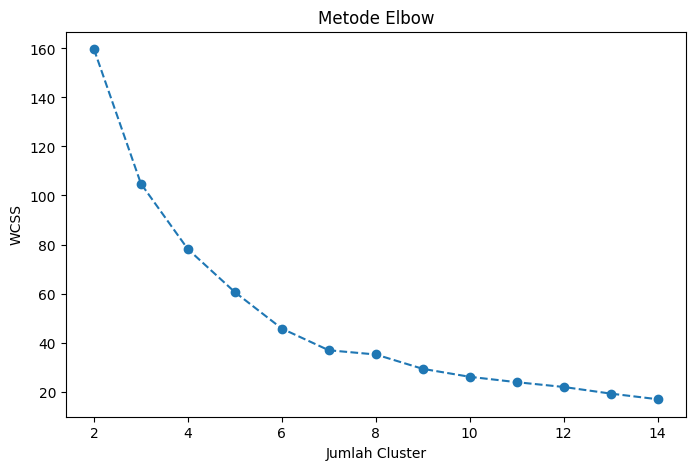

In [ ]:
# Visualisasi hasil Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(range(2, 15), wcss, marker='o', linestyle='--')
plt.title('Metode Elbow')
plt.xlabel('Jumlah Cluster')
plt.ylabel('WCSS')
plt.show()

# **Langkah 7: Evaluasi Silhouette Score**
Untuk mengevaluasi kualitas clustering, kita menggunakan Silhouette Score, yang mengukur seberapa baik objek terkelompok dengan objek lain dalam cluster yang sama dan seberapa jauh objek dari cluster lainnya.


In [ ]:
# Evaluasi Silhouette Score untuk menentukan jumlah cluster optimal
best_score = -1
optimal_clusters = 0
for n_clusters in range(2, 15):
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    cluster_labels = kmeans.fit_predict(reduced_features)
    silhouette_avg = silhouette_score(reduced_features, cluster_labels)
    print(f"Jumlah Cluster: {n_clusters}, Silhouette Score: {silhouette_avg:.2f}")

Jumlah Cluster: 2, Silhouette Score: 0.37
Jumlah Cluster: 3, Silhouette Score: 0.39
Jumlah Cluster: 4, Silhouette Score: 0.38
Jumlah Cluster: 5, Silhouette Score: 0.39
Jumlah Cluster: 6, Silhouette Score: 0.41
Jumlah Cluster: 7, Silhouette Score: 0.42
Jumlah Cluster: 8, Silhouette Score: 0.39
Jumlah Cluster: 9, Silhouette Score: 0.42
Jumlah Cluster: 10, Silhouette Score: 0.43
Jumlah Cluster: 11, Silhouette Score: 0.43
Jumlah Cluster: 12, Silhouette Score: 0.44
Jumlah Cluster: 13, Silhouette Score: 0.44
Jumlah Cluster: 14, Silhouette Score: 0.46


In [ ]:

    if silhouette_avg > best_score:
        best_score = silhouette_avg
        optimal_clusters = n_clusters


In [ ]:
core terbaik: {best_scprint(f"Jumlah cluster optimal: {optimal_clusters}, Silhouette Sore:.2f}")

Jumlah cluster optimal: 14, Silhouette Score terbaik: 0.46


# **Langkah 8: Clustering dengan K-Means**
Dengan jumlah cluster yang optimal, kita melakukan clustering menggunakan KMeans dan menambahkan label cluster ke dataset.

In [ ]:
# Melakukan clustering dengan jumlah cluster optimal
kmeans = KMeans(n_clusters=optimal_clusters, random_state=42)
df['cluster'] = kmeans.fit_predict(reduced_features) + 1  # cluster dimulai dari 1

# **Langkah 9: Visualisasi Hasil Clustering**
Kita visualisasikan hasil clustering menggunakan PCA dan plot scatter untuk melihat distribusi cluster.

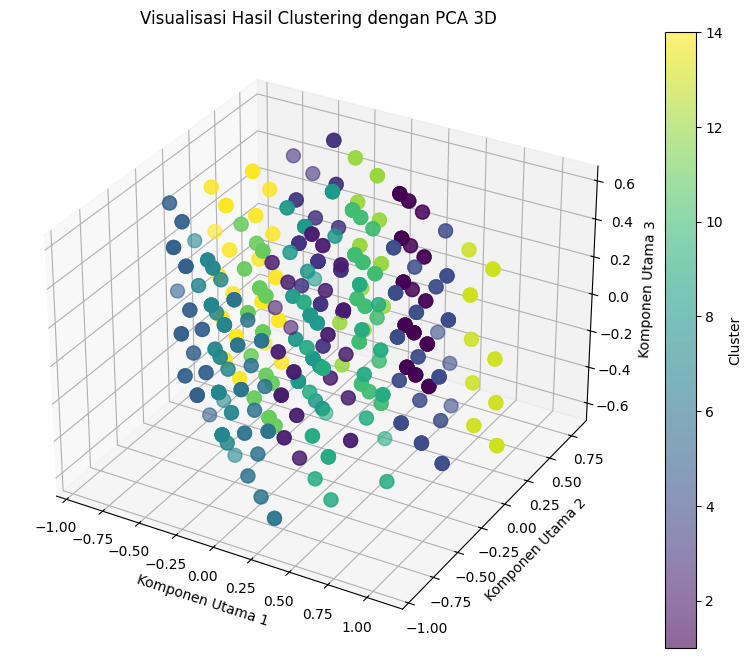

In [ ]:
# Reduksi dimensi PCA menjadi 3 komponen
pca_3d = PCA(n_components=3)
reduced_features_3d = pca_3d.fit_transform(df[numeric_features])

# Visualisasi 3D dengan scatter plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(reduced_features_3d[:, 0], reduced_features_3d[:, 1], reduced_features_3d[:, 2],
                     c=df['cluster'], cmap='viridis', alpha=0.6, s=100)

ax.set_xlabel('Komponen Utama 1')
ax.set_ylabel('Komponen Utama 2')
ax.set_zlabel('Komponen Utama 3')
ax.set_title('Visualisasi Hasil Clustering dengan PCA 3D')

plt.colorbar(scatter, label='Cluster')  # Menambahkan color bar untuk menunjukkan cluster
plt.show()

# **Langkah 10: Analisis Mendalam per Cluster**
Setelah proses clustering selesai, kita perlu menganalisis hasil clustering untuk memahami karakteristik setiap cluster.

In [ ]:
# Menganalisis rata-rata penjualan dan jumlah transaksi per cluster
for cluster in range(1, optimal_clusters + 1):
    cluster_data = df[df['cluster'] == cluster]  # Memilih data dalam cluster tertentu
    print(f"\nCluster {cluster}: Karakteristik Pelanggan")
    print(f"- Rata-rata Penjualan: {cluster_data['total_sales'].mean():.2f}")
    print(f"- Jumlah Transaksi: {len(cluster_data)}")


Cluster 1: Karakteristik Pelanggan
- Rata-rata Penjualan: 0.61
- Jumlah Transaksi: 73

Cluster 2: Karakteristik Pelanggan
- Rata-rata Penjualan: 0.33
- Jumlah Transaksi: 54

Cluster 3: Karakteristik Pelanggan
- Rata-rata Penjualan: 0.25
- Jumlah Transaksi: 54

Cluster 4: Karakteristik Pelanggan
- Rata-rata Penjualan: 0.70
- Jumlah Transaksi: 70

Cluster 5: Karakteristik Pelanggan
- Rata-rata Penjualan: 0.02
- Jumlah Transaksi: 39

Cluster 6: Karakteristik Pelanggan
- Rata-rata Penjualan: 0.13
- Jumlah Transaksi: 41

Cluster 7: Karakteristik Pelanggan
- Rata-rata Penjualan: 0.07
- Jumlah Transaksi: 62

Cluster 8: Karakteristik Pelanggan
- Rata-rata Penjualan: 0.31
- Jumlah Transaksi: 62

Cluster 9: Karakteristik Pelanggan
- Rata-rata Penjualan: 0.44
- Jumlah Transaksi: 56

Cluster 10: Karakteristik Pelanggan
- Rata-rata Penjualan: 0.48
- Jumlah Transaksi: 62

Cluster 11: Karakteristik Pelanggan
- Rata-rata Penjualan: 0.18
- Jumlah Transaksi: 56

Cluster 12: Karakteristik Pelanggan
- Ra

# **Langkah 11: Interpretasi Hasil Clustering dengan LLM**
Untuk memberikan interpretasi yang lebih mendalam tentang hasil clustering, kita mengintegrasikan model Google Gemini AI melalui LangChain. LLM ini membantu kita menganalisis data dengan memberikan penjelasan tentang karakteristik setiap cluster dalam bentuk tabel.

In [ ]:
# Fungsi untuk membuat tabel ringkasan hasil clustering
def create_summary_table(df):
    # Mengelompokkan data berdasarkan cluster dan menghitung rata-rata untuk beberapa kolom
    cluster_summary = df.groupby('cluster')[['unit_price', 'total_qty', 'total_sales', 'discount%']].mean()
    cluster_summary.reset_index(inplace=True)
    return cluster_summary

# Fungsi untuk melakukan interpretasi hasil clustering menggunakan LLM
def interpret_with_llm(summary_table):
    # Mengonversi summary_table menjadi string dengan format tabel yang rapi menggunakan 'tabulate'
    summary_table_str = tabulate(summary_table, headers='keys', tablefmt='grid', showindex=False)

    # Input API Key untuk model Google Gemini
    api_key = getpass("Masukkan API Key untuk Google Generative AI: ")
    llm = ChatGoogleGenerativeAI(model="gemini-1.5-flash", api_key=api_key, temperature=0.7)

    # Membuat prompt untuk LLM dalam Bahasa Indonesia
    prompt_template = ChatPromptTemplate.from_messages([
        ("system", "Anda adalah asisten AI yang membantu menjelaskan hasil clustering."),
        ("human", f"Berikut adalah data hasil clustering:\n{summary_table_str}\nTolong berikan interpretasi untuk setiap cluster dengan karakteristik utama mereka.")
    ])

    # Menjalankan LLM untuk mendapatkan interpretasi
    chain = LLMChain(llm=llm, prompt=prompt_template)
    response = chain.run(contexts=summary_table_str)

    return response

# Membuat tabel ringkasan dari data yang sudah di-cluster
summary_table = create_summary_table(df)  # Asumsikan df sudah memiliki hasil clustering

# Menampilkan tabel ringkasan
print("\n=== Tabel Ringkasan Hasil Clustering ===\n")
print(tabulate(summary_table, headers='keys', tablefmt='grid', showindex=False))  # Menampilkan tabel dengan format yang rapi

# Menampilkan hasil interpretasi LLM dalam Bahasa Indonesia
interpretation = interpret_with_llm(summary_table)
print("\nInterpretasi LLM:\n", interpretation)


=== Tabel Ringkasan Hasil Clustering ===

+-----------+--------------+-------------+---------------+-------------+
|   cluster |   unit_price |   total_qty |   total_sales |   discount% |
+===========+==============+=============+===============+=============+
|         1 |    0.477886  |    1        |     0.611192  |    0.424658 |
+-----------+--------------+-------------+---------------+-------------+
|         2 |    0.633862  |    0.37963  |     0.334437  |    0.537037 |
+-----------+--------------+-------------+---------------+-------------+
|         3 |    0.0529101 |    0.851852 |     0.249015  |    0.430556 |
+-----------+--------------+-------------+---------------+-------------+
|         4 |    0.808163  |    0.796429 |     0.704559  |    0.492857 |
+-----------+--------------+-------------+---------------+-------------+
|         5 |    0.117216  |    0        |     0.0174577 |    0.448718 |
+-----------+--------------+-------------+---------------+-------------+
|       

<ipython-input-27-0887ea438ca9>:24: LangChainDeprecationWarning: The class `LLMChain` was deprecated in LangChain 0.1.17 and will be removed in 1.0. Use :meth:`~RunnableSequence, e.g., `prompt | llm`` instead.
  chain = LLMChain(llm=llm, prompt=prompt_template)
<ipython-input-27-0887ea438ca9>:25: LangChainDeprecationWarning: The method `Chain.run` was deprecated in langchain 0.1.0 and will be removed in 1.0. Use :meth:`~invoke` instead.
  response = chain.run(contexts=summary_table_str)



Interpretasi LLM:
 Data yang diberikan menunjukkan hasil clustering dari suatu dataset, mungkin terkait dengan penjualan.  Setiap cluster direpresentasikan oleh rata-rata ternormalisasi dari beberapa variabel: `unit_price`, `total_qty`, `total_sales`, dan `discount%`.  Nilai-nilai ini kemungkinan telah dinormalisasi ke rentang 0-1. Mari kita coba menginterpretasikan setiap cluster berdasarkan karakteristik utama:

**Interpretasi Cluster:**

* **Cluster 1:** Harga satuan menengah, kuantitas terjual rendah (1 unit), total penjualan rendah, diskon menengah.  Mungkin mewakili produk dengan margin keuntungan sedang, yang terjual sedikit.

* **Cluster 2:** Harga satuan menengah ke atas, kuantitas terjual rendah, total penjualan rendah, diskon tinggi.  Ini mungkin produk dengan harga yang relatif tinggi, tetapi terjual sedikit karena diskon yang besar.

* **Cluster 3:** Harga satuan sangat rendah, kuantitas terjual tinggi, total penjualan sedang, diskon menengah. Ini mungkin mewakili produk 

# **Kesimpulan**
Proses clustering ini memberikan wawasan yang lebih dalam mengenai pola pembelian dalam dataset transaksi. Dengan menggunakan PCA untuk reduksi dimensi, kita dapat memvisualisasikan hasil clustering dengan lebih jelas. Meskipun Silhouette Score menunjukkan nilai di bawah 0.5, yang berarti clustering masih bisa diperbaiki, kita telah berhasil
mengidentifikasi beberapa cluster yang memiliki karakteristik berbeda.

Melalui LLM, interpretasi hasil clustering dapat dilakukan secara otomatis, memberikan penjelasan yang lebih terstruktur dalam bentuk tabel. Secara keseluruhan, proyek ini menyediakan pipeline lengkap untuk analisis clustering yang disertai dengan penafsiran otomatis menggunakan model bahasa canggih.